# Survival Energy
## Análise de dados, segurança e Pesquisa Operacional
Estudo acadêmico com dados simulados de outubro de 2026. Execute **Ambiente de execução > Executar tudo**. A primeira execução cria a base determinística (semente 20261117), sem rede e sem acessar contas. Para analisar o CSV entregue, envie `base_original.csv` para a sessão antes de executar.

Bibliotecas: Python 3.10+, NumPy, SciPy 1.9+ e Matplotlib. O Colab normalmente já fornece essas bibliotecas. Se necessário: `%pip install numpy scipy matplotlib`. Os arquivos são gravados em `resultados/`.

Não há dados reais de clientes. Margem de contribuição não é lucro líquido. Os modelos de produção e transporte são cenários de decisão distintos do histórico; as 600 peças do transporte podem incluir estoque anterior.

In [3]:
# Survival Energy: estudo simulado, sem dados reais de clientes.
import csv,json,random,statistics,math,hashlib,io
from pathlib import Path
from datetime import date,timedelta
BASE=Path.cwd()
OUT=BASE/'resultados'; OUT.mkdir(exist_ok=True)
def gravar_csv(path,rows):
    with Path(path).open('w',encoding='utf-8-sig',newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
def gerar_base():
    rng=random.Random(20261117); rows=[];item=0
    for pedido in range(1,241):
        reg=rng.choices(['Sudeste','Sul','Nordeste'],[.5,.3,.2])[0]
        frete={'Sudeste':18,'Sul':26,'Nordeste':38}[reg]+rng.choice([0,2,4,6])
        if pedido in [35,80,155,220]:frete+=70
        dia=(date(2026,10,1)+timedelta(days=rng.randrange(31))).isoformat()
        for linha in range(1,1+rng.choice([1,1,2])):
            item+=1;cat=rng.choices(['Camiseta','Moletom'],[.65,.35])[0]
            q=rng.choices([1,2,3,4],[.55,.3,.1,.05])[0]
            preco,custo=(90,40) if cat=='Camiseta' else (180,95)
            desconto=round(q*preco*rng.choice([0,0,.05,.1]),2)
            rows.append(dict(item_id=f'I{item:04d}',pedido_id=f'P{pedido:04d}',data=dia,produto=cat,tamanho=rng.choice(['P','M','M','G','G','GG']),quantidade=str(q),preco_unitario=str(preco),desconto_item=str(desconto),custo_unitario=str(custo),regiao=reg,frete_pedido=str(frete)))
    rows[5]['produto']=' camiseta ';rows[10]['tamanho']=' m '
    for idx,key,val in [(15,'quantidade','-1'),(25,'preco_unitario',''),(40,'data','2026-02-30'),(50,'desconto_item','9999'),(60,'regiao','=1+1')]:rows[idx][key]=val
    rows.append(dict(rows[1]))
    return rows
CAMPOS=['item_id','pedido_id','data','produto','tamanho','quantidade','preco_unitario','desconto_item','custo_unitario','regiao','frete_pedido']
def validar_linha(r):
    if set(r)!=set(CAMPOS):raise ValueError('Esquema inesperado')
    if any(str(v).lstrip().startswith(('=','+','@','\t','\r')) for v in r.values()):raise ValueError('Conteúdo incompatível com o esquema')
    if len(str(r))>4000:raise ValueError('Linha excessivamente longa')
    r=dict(r);r['produto']=r['produto'].strip().title();r['tamanho']=r['tamanho'].strip().upper();r['regiao']=r['regiao'].strip()
    if not (r['item_id'].startswith('I') and r['item_id'][1:].isdigit() and r['pedido_id'].startswith('P') and r['pedido_id'][1:].isdigit()):raise ValueError('Identificador inválido')
    d=date.fromisoformat(r['data'])
    if not date(2026,10,1)<=d<=date(2026,10,31):raise ValueError('Data fora do período')
    if r['produto'] not in ['Camiseta','Moletom'] or r['tamanho'] not in ['P','M','G','GG'] or r['regiao'] not in ['Sudeste','Sul','Nordeste']:raise ValueError('Categoria inválida')
    q=float(r['quantidade'])
    if not math.isfinite(q) or q!=int(q) or not 1<=q<=100:raise ValueError('Quantidade inválida')
    r['quantidade']=int(q)
    for k in ['preco_unitario','desconto_item','custo_unitario','frete_pedido']:
        v=float(r[k])
        if not math.isfinite(v) or not 0<=v<=100000:raise ValueError('Valor numérico inválido')
        r[k]=v
    if r['preco_unitario']<=0 or r['desconto_item']>q*r['preco_unitario']:raise ValueError('Preço ou desconto inválido')
    return r
def limpar(raw):
    valid=[];log=[];vistos=set();pedidos={}
    for num,r in enumerate(raw,2):
        try:
            v=validar_linha(r)
            if v['item_id'] in vistos:raise ValueError('Item duplicado')
            assinatura=(v['data'],v['regiao'],v['frete_pedido'])
            if v['pedido_id'] in pedidos and pedidos[v['pedido_id']]!=assinatura:raise ValueError('Pedido inconsistente')
            vistos.add(v['item_id']);pedidos[v['pedido_id']]=assinatura
            mudancas=[k for k in ['produto','tamanho','regiao'] if str(r[k])!=str(v[k])]
            if mudancas:log.append(dict(linha=num,item_id=r['item_id'],acao='normalizar',motivo=', '.join(mudancas)))
            valid.append(v)
        except (ValueError,TypeError,KeyError,OverflowError) as e:log.append(dict(linha=num,item_id=('I'+r['item_id'][1:] if str(r.get('item_id','')).startswith('I') and str(r.get('item_id',''))[1:].isdigit() else 'ID_INVALIDO'),acao='excluir',motivo=str(e)))
    return valid,log
def percentil(vals,p):
    s=sorted(vals);i=(len(s)-1)*p;a=int(i);b=min(a+1,len(s)-1);return s[a]+(s[b]-s[a])*(i-a)
def analisar(rows):
    pedidos={};prod={};reg={};tamanhos={}
    for r in rows:
        receita=r['quantidade']*r['preco_unitario']-r['desconto_item'];margem=receita-r['quantidade']*r['custo_unitario']
        r.update(receita=receita,margem=margem)
        p=pedidos.setdefault(r['pedido_id'],dict(receita=0,quantidade=0,frete=r['frete_pedido']))
        p['receita']+=receita;p['quantidade']+=r['quantidade']
        for grupo,key in [(prod,r['produto']),(reg,r['regiao']),(tamanhos,r['tamanho'])]:
            x=grupo.setdefault(key,dict(pecas=0,receita=0,margem=0));x['pecas']+=r['quantidade'];x['receita']+=receita;x['margem']+=margem
    vals=[p['receita'] for p in pedidos.values()];quant=[p['quantidade'] for p in pedidos.values()];fretes=[p['frete'] for p in pedidos.values()]
    mean=statistics.mean(vals);sd=statistics.stdev(vals);n=len(vals)
    assim=n/((n-1)*(n-2))*sum(((v-mean)/sd)**3 for v in vals)
    q1,q3=percentil(fretes,.25),percentil(fretes,.75);lim=q3+1.5*(q3-q1)
    out=[k for k,v in pedidos.items() if v['frete']>lim]
    resumo=dict(linhas_validas=len(rows),pedidos=n,pecas=sum(r['quantidade'] for r in rows),receita=round(sum(vals),2),margem=round(sum(r['margem'] for r in rows),2),frete_total=sum(fretes),frete_medio=statistics.mean(fretes),ticket_medio=mean,ticket_mediana=statistics.median(vals),ticket_desvio=sd,ticket_assimetria=assim,pearson_quant_receita=statistics.correlation(quant,vals),limite_outlier_frete=lim,pedidos_outliers=out,produtos=prod,regioes=reg,tamanhos=tamanhos)
    return resumo,pedidos
def producao_enum(horas=260):
    viaveis=[(50*c+85*m,c,m) for c in range(401) for m in range(201) if .4*c+.9*m<=horas+1e-9 and 1.2*c+2.5*m<=750+1e-9 and 40*c+95*m<=30000 and c+m<=600]
    return max(viaveis)
def transporte_enum(oferta_a=350):
    # Oferta total excedente é permitida; o plano deve atender exatamente a demanda.
    best=None
    for a0 in range(301):
        for a1 in range(181):
            # A rota Nordeste do A é mais cara; escolher o menor a2 viável para estes a0,a1.
            a2=max(0,600-300-a0-a1)
            if a2>120 or a0+a1+a2>oferta_a:continue
            x=[a0,a1,a2,300-a0,180-a1,120-a2]
            z=sum(c*v for c,v in zip([4,7,12,8,5,6],x))
            if best is None or z<best[0]:best=(z,x)
    return best
def otimizar_scipy():
    import numpy as np
    from scipy.optimize import milp,Bounds,LinearConstraint
    resultados={}
    for tag,horas in [('producao_base',260),('producao_crise',200)]:
        A=np.array([[.4,.9],[1.2,2.5],[40,95],[1,1]])
        b=np.array([horas,750,30000,600])
        sol=milp(c=[-50,-85],integrality=[1,1],bounds=Bounds([0,0],[400,200]),constraints=LinearConstraint(A,[-np.inf]*4,b),options={'mip_rel_gap':0})
        assert sol.success,sol.message
        x=np.rint(sol.x).astype(int);assert np.all(A@x<=b+1e-6)
        z=int(np.dot([50,85],x));assert z==producao_enum(horas)[0]
        resultados[tag]=dict(status=sol.message,quantidades=x.tolist(),margem=z,consumo=(A@x).tolist(),folga=(b-A@x).tolist())
    for tag,oferta in [('transporte_base',350),('transporte_crise',300)]:
        A=np.array([[1,1,1,0,0,0],[0,0,0,1,1,1],[1,0,0,1,0,0],[0,1,0,0,1,0],[0,0,1,0,0,1]])
        sol=milp(c=[4,7,12,8,5,6],integrality=np.ones(6),bounds=Bounds(np.zeros(6),np.full(6,np.inf)),constraints=LinearConstraint(A,[0,0,300,180,120],[oferta,300,300,180,120]),options={'mip_rel_gap':0})
        assert sol.success,sol.message
        x=np.rint(sol.x).astype(int);uso=A@x
        assert uso[0]<=oferta and uso[1]<=300 and list(uso[2:])==[300,180,120]
        z=int(np.dot([4,7,12,8,5,6],x));assert z==transporte_enum(oferta)[0]
        resultados[tag]=dict(status=sol.message,rotas=x.tolist(),custo=z,ofertas_usadas=uso[:2].tolist(),demanda_atendida=uso[2:].tolist())
    return resultados
def testar_seguranca(raw):
    resultados=[]
    for nome,campo,valor in [('formula_csv','regiao','=1+1'),('quantidade_negativa','quantidade','-2'),('quantidade_nan','quantidade','NaN'),('desconto_excessivo','desconto_item','99999'),('data_invalida','data','2026-02-30'),('categoria_fora_lista','produto','Outro')]:
        r=dict(raw[0]);r[campo]=valor
        try:validar_linha(r);ok=False
        except (ValueError,TypeError):ok=True
        assert ok,nome
        resultados.append(dict(teste=nome,resultado='PASSOU',criterio='Entrada rejeitada antes do cálculo'))
    valid,log=limpar([raw[0],raw[0]]);assert len(valid)==1
    resultados.append(dict(teste='duplicidade',resultado='PASSOU',criterio='Um único item mantido'))
    return resultados
def graficos(rows,resumo,pedidos):
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.size':11,'figure.dpi':120})
    fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained')
    axs[0,0].bar(list(resumo['produtos']),[v['margem'] for v in resumo['produtos'].values()],color=['#283d59','#a95c45']);axs[0,0].set(title='Margem por categoria',ylabel='R$')
    axs[0,1].bar(list(resumo['regioes']),[v['pecas'] for v in resumo['regioes'].values()],color='#283d59');axs[0,1].set(title='Vendas por região',ylabel='Peças')
    axs[1,0].scatter([v['quantidade'] for v in pedidos.values()],[v['receita'] for v in pedidos.values()],alpha=.45);axs[1,0].set(title='Quantidade e receita por pedido',xlabel='Peças',ylabel='Receita após descontos (R$)')
    axs[1,1].boxplot([v['frete'] for v in pedidos.values()]);axs[1,1].set(title='Frete por pedido e valores extremos',ylabel='R$',xticks=[1],xticklabels=['Pedidos'])
    fig.suptitle('Survival Energy — outubro de 2026 — dados simulados');fig.savefig(OUT/'graficos_analise.png');plt.show()
    fig,ax=plt.subplots(figsize=(8,4));ax.bar(['P','M','G','GG'],[resumo['tamanhos'][t]['pecas'] for t in ['P','M','G','GG']],color='#283d59');ax.set(title='Quantidade vendida por tamanho — simulação',xlabel='Tamanho',ylabel='Peças');fig.tight_layout();fig.savefig(OUT/'vendas_tamanho.png');plt.show()
def executar(usar_scipy=True,mostrar_graficos=True):
    original=BASE/'base_original.csv'
    if not original.exists():gravar_csv(original,gerar_base())
    if original.stat().st_size>5_000_000:raise ValueError('Arquivo maior que o limite de 5 MB')
    try:
        with original.open(encoding='utf-8-sig',newline='') as f:
            leitor=csv.DictReader(f,strict=True)
            if set(leitor.fieldnames or [])!=set(CAMPOS):raise ValueError('CSV sem as colunas obrigatórias')
            raw=list(leitor)
    except (UnicodeError,csv.Error) as e:raise ValueError('CSV ilegível ou malformado') from e
    if not raw:raise ValueError('CSV sem registros')
    if len(raw)>10000:raise ValueError('Mais de 10000 itens')
    digest=hashlib.sha256(original.read_bytes()).hexdigest()
    rows,log=limpar(raw)
    if len(rows)<3:raise ValueError('Dados válidos insuficientes para análise')
    resumo,pedidos=analisar(rows)
    resumo['linhas_originais']=len(raw);resumo['excluidas']=len(raw)-len(rows);resumo['normalizadas']=sum(r['acao']=='normalizar' for r in log)
    gravar_csv(OUT/'base_tratada.csv',rows);gravar_csv(OUT/'registro_tratamento.csv',log)
    testes=testar_seguranca(raw);gravar_csv(OUT/'testes_seguranca.csv',testes)
    # Plano de referência salvo antes da chamada ao otimizador.
    planos=dict(producao=[300,120],transporte=[150,100,100,150,80,20])
    (OUT/'planos_iniciais.json').write_text(json.dumps(planos,indent=2),encoding='utf-8')
    assert .4*300+.9*120<=260 and 1.2*300+2.5*120<=750 and 40*300+95*120<=30000
    assert sum(planos['transporte'][:3])<=350 and sum(planos['transporte'][3:])<=300
    assert [planos['transporte'][i]+planos['transporte'][i+3] for i in range(3)]==[300,180,120]
    resultados=otimizar_scipy() if usar_scipy else dict(producao_base=producao_enum(),producao_crise=producao_enum(200),transporte_base=transporte_enum(),transporte_crise=transporte_enum(300))
    resultado=dict(dados=resumo,otimizacao=resultados,planos_iniciais=planos,sha256_original=digest,testes=testes,metodo='SciPy MILP e conferência independente por enumeração' if usar_scipy else 'Conferência independente por enumeração')
    (OUT/'resultados.json').write_text(json.dumps(resultado,ensure_ascii=False,indent=2),encoding='utf-8')
    print(json.dumps(resultado,ensure_ascii=False,indent=2))
    if mostrar_graficos:graficos(rows,resumo,pedidos)
    return resultado

def filtrar(rows,inicio='2026-10-01',fim='2026-10-31',produto=None,regiao=None):
    if date.fromisoformat(inicio)>date.fromisoformat(fim):raise ValueError('Intervalo invertido')
    return [r for r in rows if inicio<=r['data']<=fim and (produto is None or r['produto']==produto) and (regiao is None or r['regiao']==regiao)]
def complementos(resultado):
    rows=list(csv.DictReader((OUT/'base_tratada.csv').open(encoding='utf-8-sig')))
    for r in rows:
        for k in ['quantidade','receita','margem','frete_pedido']:r[k]=float(r[k])
    fretes={};vistos=set();dias={}
    for r in rows:
        dias[r['data']]=dias.get(r['data'],0)+r['receita']
        if r['pedido_id'] not in vistos:
            vistos.add(r['pedido_id']);fretes.setdefault(r['regiao'],[]).append(r['frete_pedido'])
    frete_reg=[dict(regiao=k,pedidos=len(v),frete_medio=statistics.mean(v)) for k,v in fretes.items()]
    gravar_csv(OUT/'frete_por_regiao.csv',frete_reg)
    gravar_csv(OUT/'indicadores.csv',[dict(indicador=k,valor=v) for k,v in resultado['dados'].items() if isinstance(v,(int,float))])
    gravar_csv(OUT/'solucoes_otimizacao.csv',[dict(cenario=k,valor=v.get('margem',v.get('custo')),decisao=json.dumps(v.get('quantidades',v.get('rotas')))) for k,v in resultado['otimizacao'].items()])
    segmento=filtrar(rows,'2026-10-01','2026-10-15','Camiseta','Sudeste')
    assert all(r['produto']=='Camiseta' and r['regiao']=='Sudeste' and r['data']<='2026-10-15' for r in segmento)
    gravar_csv(OUT/'exemplo_filtro.csv',segmento)
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
    datas=sorted(dias);ax[0].plot([int(d[-2:]) for d in datas],[dias[d] for d in datas],color='#283d59');ax[0].set(title='Receita diária simulada — outubro de 2026',xlabel='Dia',ylabel='R$')
    ax[1].bar([r['regiao'] for r in frete_reg],[r['frete_medio'] for r in frete_reg],color='#a95c45');ax[1].set(title='Frete médio por região',ylabel='R$ por pedido')
    fig.savefig(OUT/'periodo_e_frete.png');plt.show()
    print('Frete por região:',frete_reg,'; Linhas do filtro:',len(segmento))
    # Capacidade abaixo do limiar: oferta total 550 < demanda 600.
    from scipy.optimize import milp,Bounds,LinearConstraint
    import numpy as np
    A=np.array([[1,1,1,0,0,0],[0,0,0,1,1,1],[1,0,0,1,0,0],[0,1,0,0,1,0],[0,0,1,0,0,1]])
    sol=milp(c=[4,7,12,8,5,6],integrality=np.ones(6),bounds=Bounds(np.zeros(6),np.full(6,np.inf)),constraints=LinearConstraint(A,[0,0,300,180,120],[250,300,300,180,120]))
    assert sol.status==2 and sol.x is None
    (OUT/'teste_inviabilidade.txt').write_text('PASSOU: oferta A=250 e B=300; demanda=600. Solver declarou inviabilidade. Nenhuma solução inexistente foi interpretada.',encoding='utf-8')
    print('Teste de inviabilidade passou:',sol.message)



## 1 ETL e indicadores
Validamos esquema, limites, categorias, datas e identificadores. Itens com dados insuficientes são excluídos com motivo; não imputamos preços. O frete é contado uma vez por pedido. As exclusões podem reduzir o valor de pedidos com outros itens mantidos; essa limitação é considerada na interpretação. Receita e margem acompanham o objetivo de decidir o mix; frete médio acompanha a distribuição.

## 2 Estatística e gráficos
Calculamos média, mediana, desvio padrão amostral, assimetria ajustada, Pearson e outliers de frete por 1,5 IQR. Correlação não demonstra causalidade e o histórico é uma simulação.

## 3 Modelos matemáticos
Produção: maximizar 50c + 85m, com 0,4c + 0,9m ≤ 260 horas; 1,2c + 2,5m ≤ 750 m²; 40c + 95m ≤ 30000 reais; c + m ≤ 600; c ≤ 400; m ≤ 200; c,m inteiros não negativos. Crise: somente horas caem para 200.

Transporte: minimizar 4xAS + 7xAL + 12xAN + 8xBS + 5xBL + 6xBN. A oferta é 350 peças no A e 300 no B. As demandas exatas são 300 (Sudeste), 180 (Sul) e 120 (Nordeste). Todas as variáveis são inteiras não negativas. Crise: somente a oferta A cai para 300.

O solver SciPy MILP é conferido por um algoritmo independente que percorre todas as combinações relevantes do pequeno problema. Não usamos Excel Solver.

{
  "dados": {
    "linhas_validas": 322,
    "pedidos": 237,
    "pecas": 524,
    "receita": 58189.5,
    "margem": 29254.5,
    "frete_total": 6826.0,
    "frete_medio": 28.80168776371308,
    "ticket_medio": 245.5253164556962,
    "ticket_mediana": 180.0,
    "ticket_desvio": 151.2867457548977,
    "ticket_assimetria": 1.2541021855990044,
    "pearson_quant_receita": 0.84051540354489,
    "limite_outlier_frete": 47.0,
    "pedidos_outliers": [
      "P0035",
      "P0080",
      "P0155",
      "P0220"
    ],
    "produtos": {
      "Camiseta": {
        "pecas": 379,
        "receita": 32881.5,
        "margem": 17721.5
      },
      "Moletom": {
        "pecas": 145,
        "receita": 25308.0,
        "margem": 11533.0
      }
    },
    "regioes": {
      "Nordeste": {
        "pecas": 99,
        "receita": 11272.5,
        "margem": 5607.5
      },
      "Sudeste": {
        "pecas": 250,
        "receita": 27423.0,
        "margem": 13848.0
      },
      "Sul": {
        "p

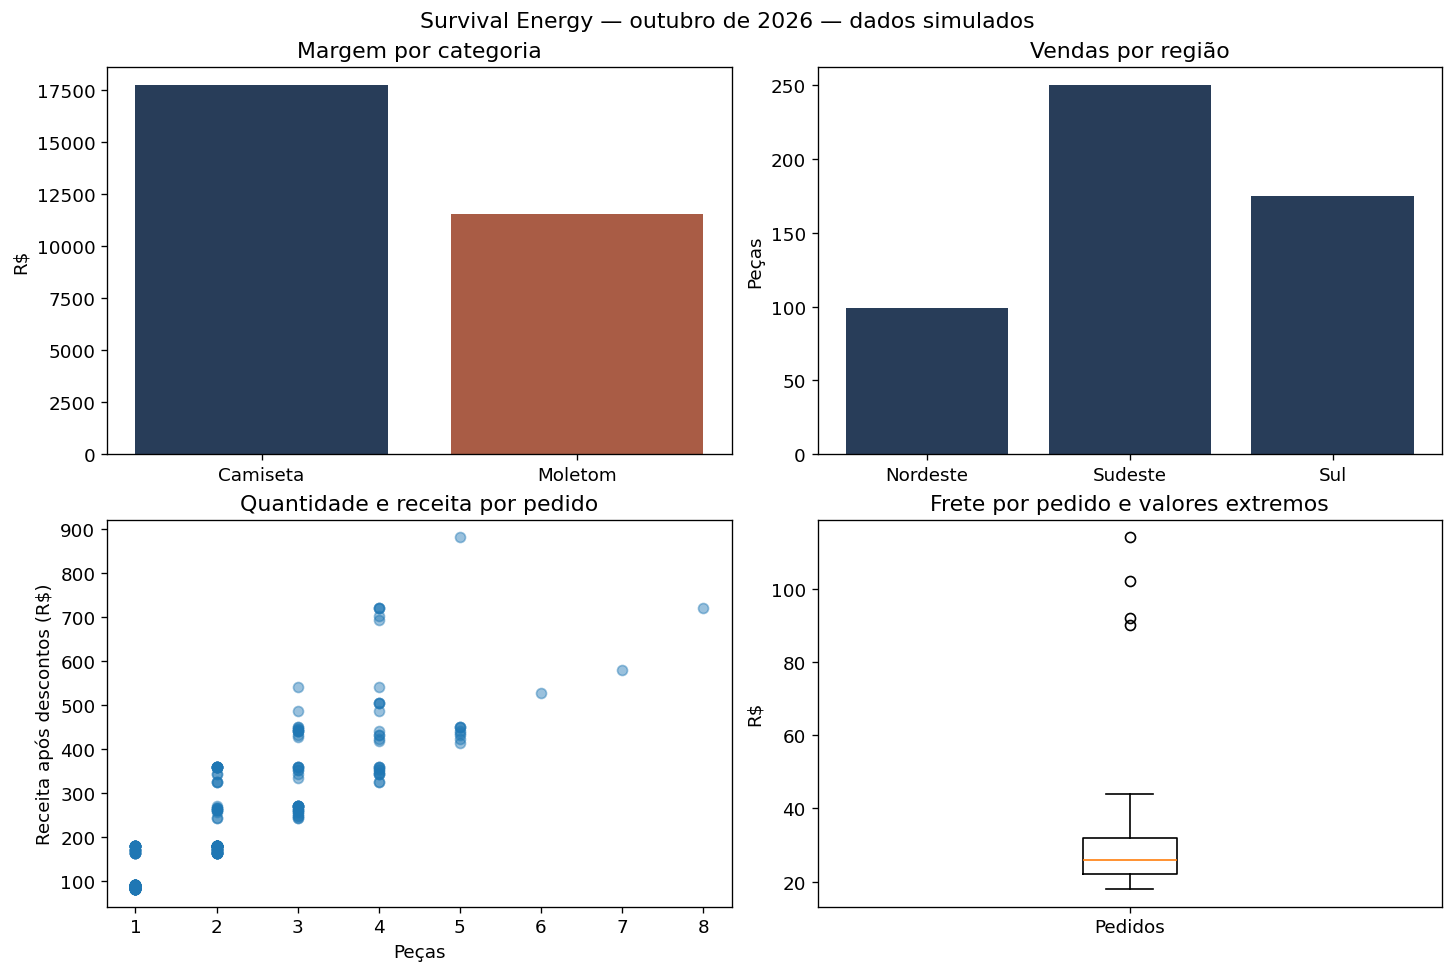

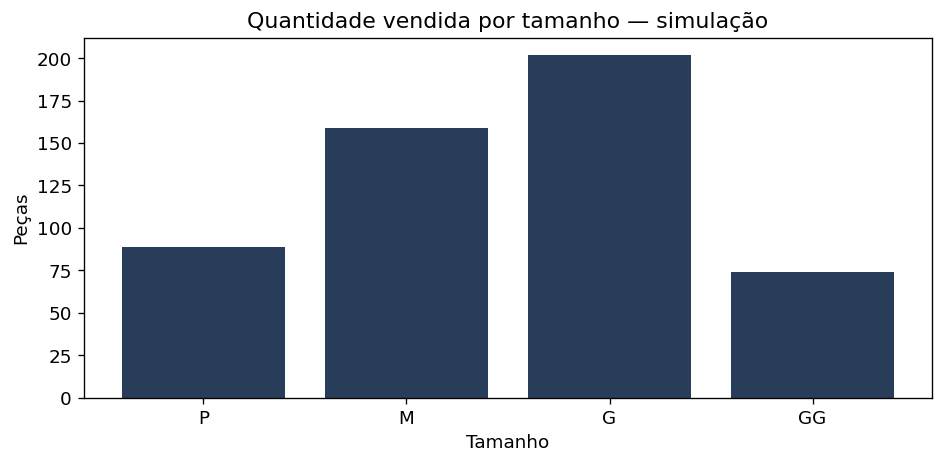

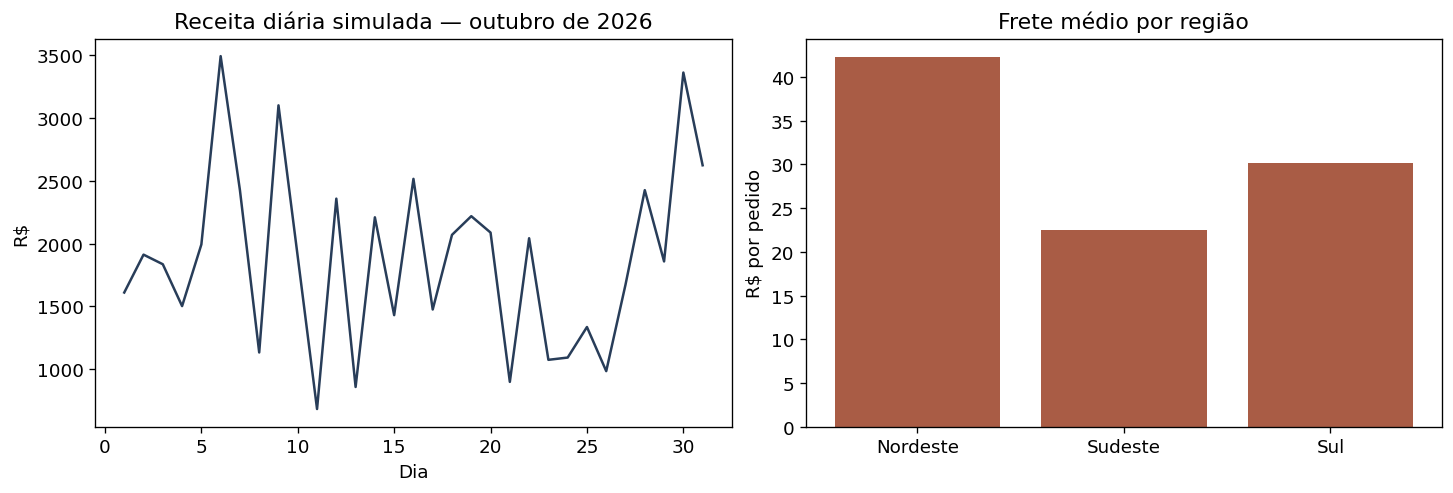

Frete por região: [{'regiao': 'Nordeste', 'pedidos': 48, 'frete_medio': 42.291666666666664}, {'regiao': 'Sudeste', 'pedidos': 117, 'frete_medio': 22.46153846153846}, {'regiao': 'Sul', 'pedidos': 72, 'frete_medio': 30.11111111111111}] ; Linhas do filtro: 54
Teste de inviabilidade passou: The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)


In [4]:
resultado = executar(usar_scipy=True, mostrar_graficos=True)
complementos(resultado)

## 4 Conferência de amostra e exportação
A primeira linha válida é conferida manualmente pela mesma definição dos indicadores. Os testes negativos exercitam entradas inválidas, sem executar conteúdo recebido. SHA-256 detecta mudanças em relação à cópia de referência, mas não autentica a origem se um invasor substituir também o manifesto.

In [5]:
r=next(csv.DictReader((OUT/'base_tratada.csv').open(encoding='utf-8-sig')))
print('Amostra:',r['item_id'], 'Receita =', r['quantidade'],'x',r['preco_unitario'],'-',r['desconto_item'],'=',r['receita'])
import sys, numpy, scipy, matplotlib
versoes={'python':sys.version,'numpy':numpy.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__}
(OUT/'versoes.json').write_text(json.dumps(versoes,indent=2),encoding='utf-8')
print(versoes)
import shutil
shutil.make_archive('survival_resultados','zip',OUT)
print('Execução concluída; resultados em survival_resultados.zip')

Amostra: I0001 Receita = 1 x 90.0 - 4.5 = 85.5
{'python': '3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]', 'numpy': '2.4.6', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}
Execução concluída; resultados em survival_resultados.zip


## 5 Interpretação
Compare os planos de referência com as soluções do solver: o plano inicial da produção vale 25.200,00 reais e o plano inicial do transporte custa 4.220,00 reais. Verifique os resultados impressos antes de explicar os ganhos. A redução de horas e a perda de capacidade de um centro representam riscos distintos; a queda de capacidade logística não é automaticamente consequência da produção.

Referências: SCIPY. milp. https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html. OWASP. Input Validation Cheat Sheet. https://cheatsheetseries.owasp.org/cheatsheets/Input_Validation_Cheat_Sheet.html. Acesso em: 17 nov. 2026.